# Notebook 1: prep and face crop (BeepFake / ExDDV, FaceForensics++)

Per fake video: 5 equally spaced frames, one face box per video (union of per-frame detections plus margin, made square), 224x224 PNG crops, and the human click coordinates converted into crop coordinates.

**Needs:** dataset `kishlaytejeswi/vlm-nlp` attached. Internet on (only to fetch the small YuNet face detector; Haar fallback is built in). CPU is enough.

**Output:** `/kaggle/working/prep/` with `crops/{manipulation}/{stem}/{0..4}.png`, a `meta.json` per video, and `metadata.csv`. After "Save & Run All", use Output -> New Dataset to make it a Kaggle dataset for notebooks 2-4.

**Click convention (my choice, change if you disagree):** a sampled frame rarely coincides with an annotated click frame, so every sampled frame gets the *nearest-in-time* click, with its frame distance stored (`dist`). All clicks are also stored converted to crop coordinates, so notebook 2 can filter or weight by `dist`.

In [1]:
import os, re, json, ast, time, math, random, urllib.request, multiprocessing as mp
from pathlib import Path
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

cv2.setNumThreads(1)
print("cv2", cv2.__version__, "| CPUs:", os.cpu_count())

INPUT_ROOT = Path("/kaggle/input")
OUT_DIR  = Path("/kaggle/working/prep")
CROP_DIR = OUT_DIR / "crops"
CROP_DIR.mkdir(parents=True, exist_ok=True)

N_FRAMES  = 5
CROP_SIZE = 224
MARGIN    = 1.3      # crop side = MARGIN * max(union box w, h)
MIN_SCORE = 0.6      # YuNet score threshold
N_WORKERS = max(1, (os.cpu_count() or 2))
SEED = 0

cv2 4.14.0 | CPUs: 4


## 1. Load CSV, find videos, sanity checks

In [2]:
hits = list(INPUT_ROOT.rglob("ExDDV_faceforensics.csv"))
assert hits, "CSV not found under /kaggle/input. Is the dataset attached?"
CSV_PATH = hits[0]; DATA_ROOT = CSV_PATH.parent
print("CSV:", CSV_PATH)

df = pd.read_csv(CSV_PATH)
print(df.shape); print(df.columns.tolist())
df["stem"] = df["movie_name"].astype(str).map(lambda s: Path(s).stem)
df["key"]  = df["manipulation"].astype(str) + "/" + df["stem"]
dups = df["key"].duplicated().sum()
if dups:
    print(f"WARNING: {dups} duplicate (manipulation, movie) rows; keeping the first of each")
    df = df.drop_duplicates("key").reset_index(drop=True)
print("splits:", df["split"].value_counts().to_dict())
print("methods:", df["manipulation"].value_counts().to_dict())

# index videos by (parent folder, stem), case-insensitive
video_index = {f"{p.parent.name}/{p.stem}".lower(): p for p in DATA_ROOT.rglob("*.mp4")}
print("mp4 files found:", len(video_index))
df["video_path"] = df["key"].str.lower().map(video_index)
missing = df[df.video_path.isna()]
print("rows without a video file:", len(missing))
if len(missing): print(missing[["movie_name","manipulation"]].head())
df = df[df.video_path.notna()].reset_index(drop=True)
print("usable videos:", len(df))

CSV: /kaggle/input/datasets/kishlaytejeswi/vlm-nlp/ExDDV_faceforensics.csv
(2993, 9)
['id', 'username', 'movie_name', 'text', 'dataset', 'manipulation', 'click_locations', 'difficulty', 'split']
splits: {'train': 2453, 'test': 271, 'val': 269}
methods: {'FaceSwap': 999, 'Face2Face': 997, 'FaceShifter': 997}
mp4 files found: 3000
rows without a video file: 0
usable videos: 2993


In [3]:
# Source-ID leakage check. FF++ fake names look like 890_837: check BOTH numbers.
df["id_a"] = df["stem"].str.extract(r"^(\d+)")[0]
df["id_b"] = df["stem"].str.extract(r"_(\d+)")[0]
splits = [s for s in ["train","val","test"] if s in set(df.split)]
for col in ["id_a","id_b"]:
    S = {sp: set(df.loc[df.split==sp, col].dropna()) for sp in splits}
    shared = {f"{a}&{b}": len(S[a] & S[b]) for i,a in enumerate(splits) for b in splits[i+1:]}
    print(f"{col}: shared IDs between splits ->", shared)
train_ids = set(df.loc[df.split=="train","id_a"].dropna())
n_test_leak = df[(df.split=="test") & df.id_a.isin(train_ids)].shape[0]
print(f"test videos whose first ID also appears in train: {n_test_leak} / {(df.split=='test').sum()}")

id_a: shared IDs between splits -> {'train&val': 248, 'train&test': 236, 'val&test': 48}
id_b: shared IDs between splits -> {'train&val': 248, 'train&test': 236, 'val&test': 48}
test videos whose first ID also appears in train: 256 / 271


In [4]:
def parse_clicks(s):
    if isinstance(s, dict): d = s
    else:
        try: d = json.loads(s)
        except Exception: d = ast.literal_eval(s)
    return {int(k): (float(v["x"]), float(v["y"])) for k, v in d.items()}

bad = 0; parsed = []
for s in df["click_locations"]:
    try: parsed.append(parse_clicks(s))
    except Exception: parsed.append({}); bad += 1
df["clicks"] = parsed
n_cl = df.clicks.map(len)
xs = [x for c in df.clicks for x, y in c.values()]; ys = [y for c in df.clicks for x, y in c.values()]
print(f"unparsable click fields: {bad} | clicks/video mean {n_cl.mean():.2f}, min {n_cl.min()}, max {n_cl.max()}")
print(f"x range [{min(xs):.3f}, {max(xs):.3f}], y range [{min(ys):.3f}, {max(ys):.3f}]  (should be within [0, 1])")

unparsable click fields: 0 | clicks/video mean 4.59, min 1, max 14
x range [0.112, 0.925], y range [0.065, 1.003]  (should be within [0, 1])


## 2. Face detector (YuNet, Haar fallback)

In [5]:
YUNET_URL  = "https://github.com/opencv/opencv_zoo/raw/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx"
YUNET_PATH = Path("/tmp/yunet.onnx")

def ensure_yunet():
    try:
        if not hasattr(cv2, "FaceDetectorYN"): return False
        if not YUNET_PATH.exists() or YUNET_PATH.stat().st_size < 100_000:
            urllib.request.urlretrieve(YUNET_URL, YUNET_PATH)
        return YUNET_PATH.stat().st_size > 100_000     # a tiny file would be an LFS pointer, not the model
    except Exception as e:
        print("YuNet unavailable:", repr(e)); return False

USE_YUNET = ensure_yunet()
print("YuNet:", USE_YUNET, "(otherwise Haar cascade only; that works but is weaker)")

class FaceDet:
    def __init__(self):
        self.yunet = cv2.FaceDetectorYN.create(str(YUNET_PATH), "", (320, 320), MIN_SCORE, 0.3, 5) if USE_YUNET else None
        self.haar = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")
    def __call__(self, bgr):
        H, W = bgr.shape[:2]
        if self.yunet is not None:
            self.yunet.setInputSize((W, H))
            _, faces = self.yunet.detect(bgr)
            if faces is not None and len(faces):
                f = max(faces, key=lambda r: r[2] * r[3])
                return (float(f[0]), float(f[1]), float(f[2]), float(f[3])), "yunet"
        gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
        r = self.haar.detectMultiScale(gray, 1.1, 5, minSize=(max(40, W // 20),) * 2)
        if len(r):
            f = max(r, key=lambda q: q[2] * q[3])
            return tuple(float(v) for v in f), "haar"
        return None, "none"

DET = FaceDet()

YuNet: True (otherwise Haar cascade only; that works but is weaker)


## 3. Per-video processing

In [6]:
def sample_indices(n, k=N_FRAMES):
    return [min(n - 1, int((i + 0.5) * n / k)) for i in range(k)]   # centres of k equal segments

def read_frames(path):
    cap = cv2.VideoCapture(str(path))
    n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if n < N_FRAMES: cap.release(); return None
    idxs = sample_indices(n); want = set(idxs); frames = {}
    for i in range(max(idxs) + 1):          # sequential grab: seeking can be inexact
        if not cap.grab(): break
        if i in want:
            ok, f = cap.retrieve()
            if ok: frames[i] = f
    cap.release()
    if any(i not in frames for i in idxs): return None
    return n, idxs, [frames[i] for i in idxs]

def make_box(dets, W, H):
    """union of per-frame face boxes -> square with margin, clamped inside the frame. returns x0, y0, side"""
    if not dets:
        s = min(H, W); return (W - s) // 2, (H - s) // 2, s
    x0 = min(d[0] for d in dets); y0 = min(d[1] for d in dets)
    x1 = max(d[0] + d[2] for d in dets); y1 = max(d[1] + d[3] for d in dets)
    cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
    s = int(round(min(max(x1 - x0, y1 - y0) * MARGIN, H, W)))
    bx = int(round(min(max(cx - s / 2, 0), W - s)))
    by = int(round(min(max(cy - s / 2, 0), H - s)))
    return bx, by, s

def process(job):
    key, path, manip, stem, clicks = job
    out = CROP_DIR / manip / stem
    meta_p = out / "meta.json"
    if meta_p.exists(): return key, "skip"
    try:
        got = read_frames(path)
        if got is None: return key, "read_fail"
        n, idxs, frames = got
        H, W = frames[0].shape[:2]
        dets, srcs = [], []
        for f in frames:
            b, s = DET(f); srcs.append(s)
            if b is not None: dets.append(b)
        x0, y0, s = make_box(dets, W, H)

        out.mkdir(parents=True, exist_ok=True)
        paths = []
        for i, f in enumerate(frames):
            crop = cv2.resize(f[y0:y0 + s, x0:x0 + s], (CROP_SIZE, CROP_SIZE), interpolation=cv2.INTER_AREA)
            cv2.imwrite(str(out / f"{i}.png"), crop)       # PNG: lossless, so artifacts are not smoothed away
            paths.append(f"crops/{manip}/{stem}/{i}.png")

        conv = []
        for k, (x, y) in sorted(clicks.items()):
            cx, cy = (x * W - x0) / s, (y * H - y0) / s
            conv.append({"frame": k, "x": cx, "y": cy, "in_crop": bool(0 <= cx <= 1 and 0 <= cy <= 1)})
        per_frame = []
        if conv:
            ks = np.array([c["frame"] for c in conv])
            for fi in idxs:
                c = conv[int(np.argmin(np.abs(ks - fi)))]
                per_frame.append({"frame_idx": fi, "click_frame": c["frame"], "dist": int(abs(c["frame"] - fi)),
                                  "x": c["x"], "y": c["y"], "in_crop": c["in_crop"]})
        meta = {"key": key, "n_frames": n, "H": H, "W": W, "frame_idx": idxs, "box": [x0, y0, s],
                "n_det": len(dets), "det_sources": srcs, "crop_paths": paths,
                "clicks_crop": conv, "click_targets": per_frame,
                "click_beyond_video": bool(conv and max(c["frame"] for c in conv) >= n)}
        with open(meta_p, "w") as fh: json.dump(meta, fh)      # written last: its presence means "done"
        return key, "ok"
    except Exception as e:
        return key, "error:" + repr(e)

def make_jobs(frame):
    return [(r.key, str(r.video_path), r.manipulation, r.stem, r.clicks) for r in frame.itertuples()]

## 4. Quick check on 6 random videos before the full run

('FaceSwap/744_674', 'ok')
('FaceShifter/548_632', 'ok')
('FaceShifter/823_584', 'ok')
('Face2Face/483_370', 'ok')
('FaceShifter/698_693', 'ok')
('FaceShifter/057_070', 'ok')


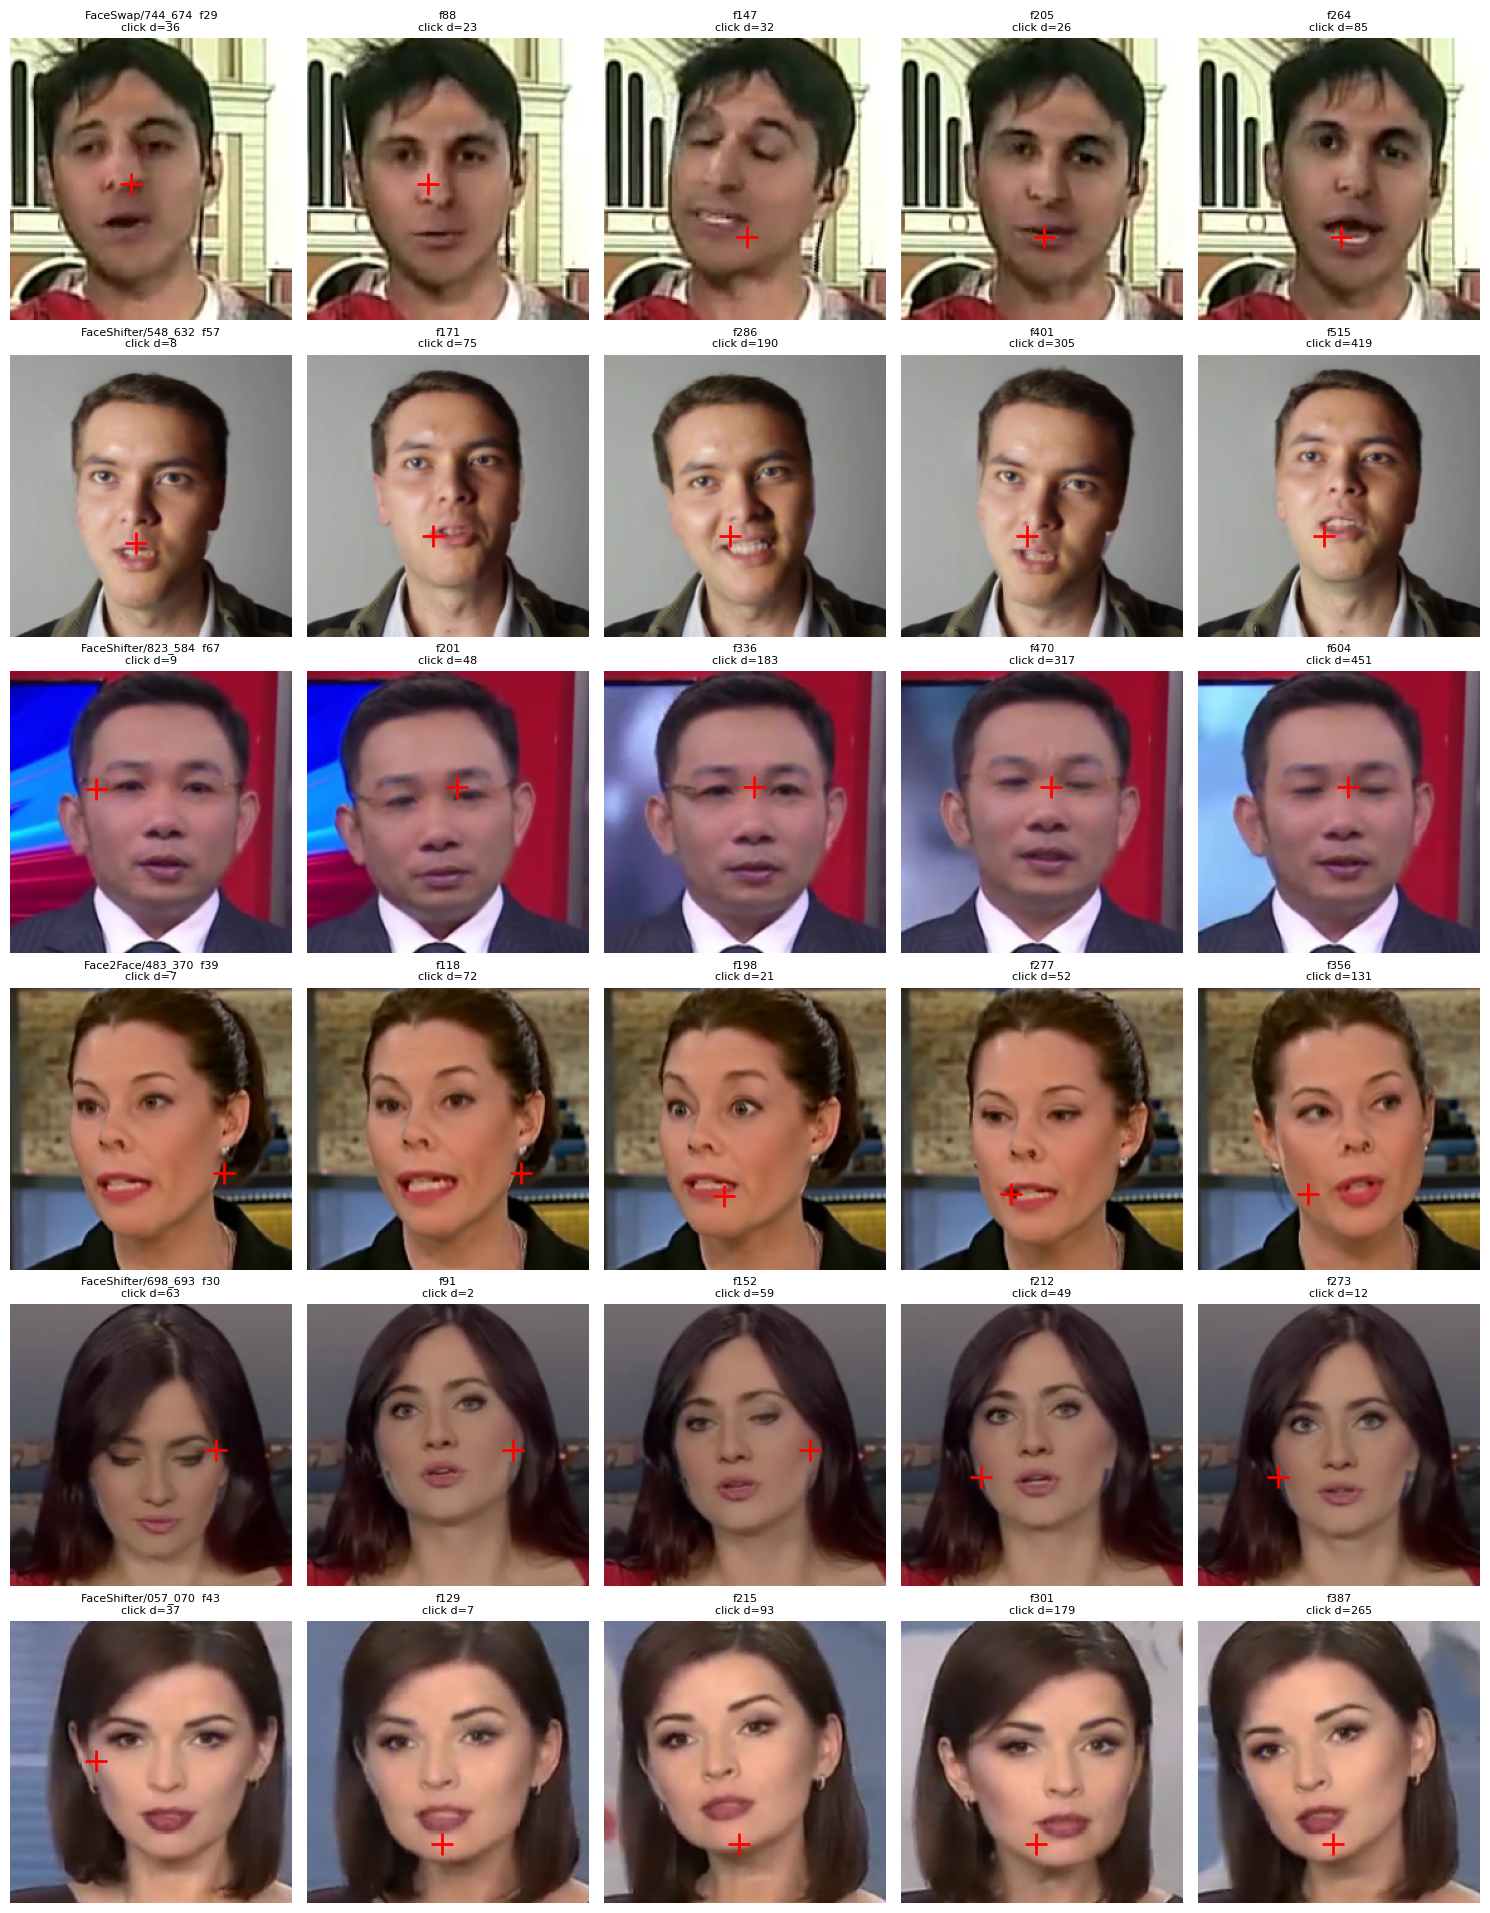

FaceSwap/744_674 -> The features are slightly crooked. The nose is distorted. The mouth looks unnatural, especially the teeth.
FaceShifter/548_632 -> The mouth is distorting. There are many visual glitches around the mouth, eyebrows and right side of the face.
FaceShifter/823_584 -> There are some residual artifacts with glasses.
Face2Face/483_370 -> There is a flickering on the face when the person is blinking. Artifacts are also on the right side of the face.
FaceShifter/698_693 -> There are some blurred areas around each ear.
FaceShifter/057_070 -> The gaze is unnatural.


In [7]:
def load_meta(key):
    manip, stem = key.split("/")
    return json.load(open(CROP_DIR / manip / stem / "meta.json"))

def show_samples(keys):
    fig, axes = plt.subplots(len(keys), N_FRAMES, figsize=(3 * N_FRAMES, 3.2 * len(keys)), squeeze=False)
    for r, key in enumerate(keys):
        m = load_meta(key); manip, stem = key.split("/")
        for c in range(N_FRAMES):
            ax = axes[r][c]
            ax.imshow(cv2.cvtColor(cv2.imread(str(CROP_DIR / manip / stem / f"{c}.png")), cv2.COLOR_BGR2RGB)); ax.axis("off")
            t = (key + "  " if c == 0 else "") + f"f{m['frame_idx'][c]}"
            if m["click_targets"]:
                ct = m["click_targets"][c]
                ax.plot(ct["x"] * CROP_SIZE, ct["y"] * CROP_SIZE, "r+", ms=16, mew=2)
                t += f"\nclick d={ct['dist']}" + ("" if ct["in_crop"] else " (outside crop)")
            ax.set_title(t, fontsize=8)
    plt.tight_layout(); plt.show()
    for key in keys:
        print(key, "->", str(df.loc[df.key == key, "text"].iloc[0])[:160])

test_df = df.sample(6, random_state=SEED)
for job in make_jobs(test_df): print(process(job))
show_samples(test_df.key.tolist())

Check the crops above: face centred, whole face visible, red crosses near plausible artifact spots. If crops look wrong, fix `MARGIN` / the detector before the full run.

## 5. Full run (resumable: finished videos are skipped)

In [8]:
def _init():
    global DET
    cv2.setNumThreads(1)
    DET = FaceDet()

jobs = make_jobs(df)
status = {}
t0 = time.time()
with mp.get_context("fork").Pool(N_WORKERS, initializer=_init) as pool:
    for key, st in tqdm(pool.imap_unordered(process, jobs, chunksize=4), total=len(jobs)):
        status[key] = st
print(f"done in {(time.time()-t0)/60:.1f} min")
print(pd.Series({k: v.split(":")[0] for k, v in status.items()}).value_counts().to_dict())
errs = {k: v for k, v in status.items() if v not in ("ok", "skip")}
print("failed:", len(errs)); print(list(errs.items())[:10])

  0%|          | 0/2993 [00:00<?, ?it/s]

done in 24.5 min
{'ok': 2987, 'skip': 6}
failed: 0
[]


## 6. Assemble metadata.csv and report

In [9]:
rows = [json.load(open(p)) for p in CROP_DIR.rglob("meta.json")]
meta = pd.DataFrame(rows)
meta = df[["key","movie_name","manipulation","split","text"]].merge(meta, on="key", how="inner")
print("videos with crops:", len(meta), "of", len(df))

out = meta.copy()
for c in ["frame_idx","box","det_sources","crop_paths","clicks_crop","click_targets"]:
    out[c] = out[c].map(json.dumps)
out.to_csv(OUT_DIR / "metadata.csv", index=False)
print("saved", OUT_DIR / "metadata.csv")

print("\n--- detection ---")
print("per-frame detector:", pd.Series([s for l in meta.det_sources for s in l]).value_counts().to_dict())
print("videos with <3 of 5 frames detected:", int((meta.n_det < 3).sum()), "| none detected (centre-crop fallback):", int((meta.n_det == 0).sum()))
ratio = meta.box.map(lambda b: b[2]) / meta[["H","W"]].min(axis=1)
print("crop side / short frame side:", ratio.describe().round(2).to_dict())
print("frame sizes:", meta.groupby(["W","H"]).size().sort_values(ascending=False).head(5).to_dict())

print("\n--- clicks ---")
allc = [c for l in meta.clicks_crop for c in l]
print("clicks inside crop:", f"{np.mean([c['in_crop'] for c in allc]):.3f}", f"({len(allc)} clicks)")
d = pd.Series([t["dist"] for l in meta.click_targets for t in l])
print("nearest-click distance in frames (per sampled frame):", d.describe().round(1).to_dict())
print("videos with a click frame index beyond the video length:", int(meta.click_beyond_video.sum()), "(should be 0; else frame_index is not the original frame index)")
print("videos with no clicks:", int((meta.click_targets.map(len) == 0).sum()))

size_gb = sum(p.stat().st_size for p in OUT_DIR.rglob("*") if p.is_file()) / 1e9
print(f"\noutput size: {size_gb:.2f} GB (limit about 20 GB)")

videos with crops: 2993 of 2993
saved /kaggle/working/prep/metadata.csv

--- detection ---
per-frame detector: {'yunet': 14962, 'none': 2, 'haar': 1}
videos with <3 of 5 frames detected: 0 | none detected (centre-crop fallback): 0
crop side / short frame side: {'count': 2993.0, 'mean': 0.51, 'std': 0.17, 'min': 0.17, '25%': 0.39, '50%': 0.47, '75%': 0.59, 'max': 1.0}
frame sizes: {(1280, 720): 974, (640, 480): 861, (1920, 1080): 368, (854, 480): 195, (656, 480): 132}

--- clicks ---
clicks inside crop: 0.998 (13725 clicks)
nearest-click distance in frames (per sampled frame): {'count': 14965.0, 'mean': 109.6, 'std': 135.6, 'min': 0.0, '25%': 17.0, '50%': 58.0, '75%': 158.0, 'max': 1460.0}
videos with a click frame index beyond the video length: 127 (should be 0; else frame_index is not the original frame index)
videos with no clicks: 0

output size: 1.16 GB (limit about 20 GB)


flagged: 76


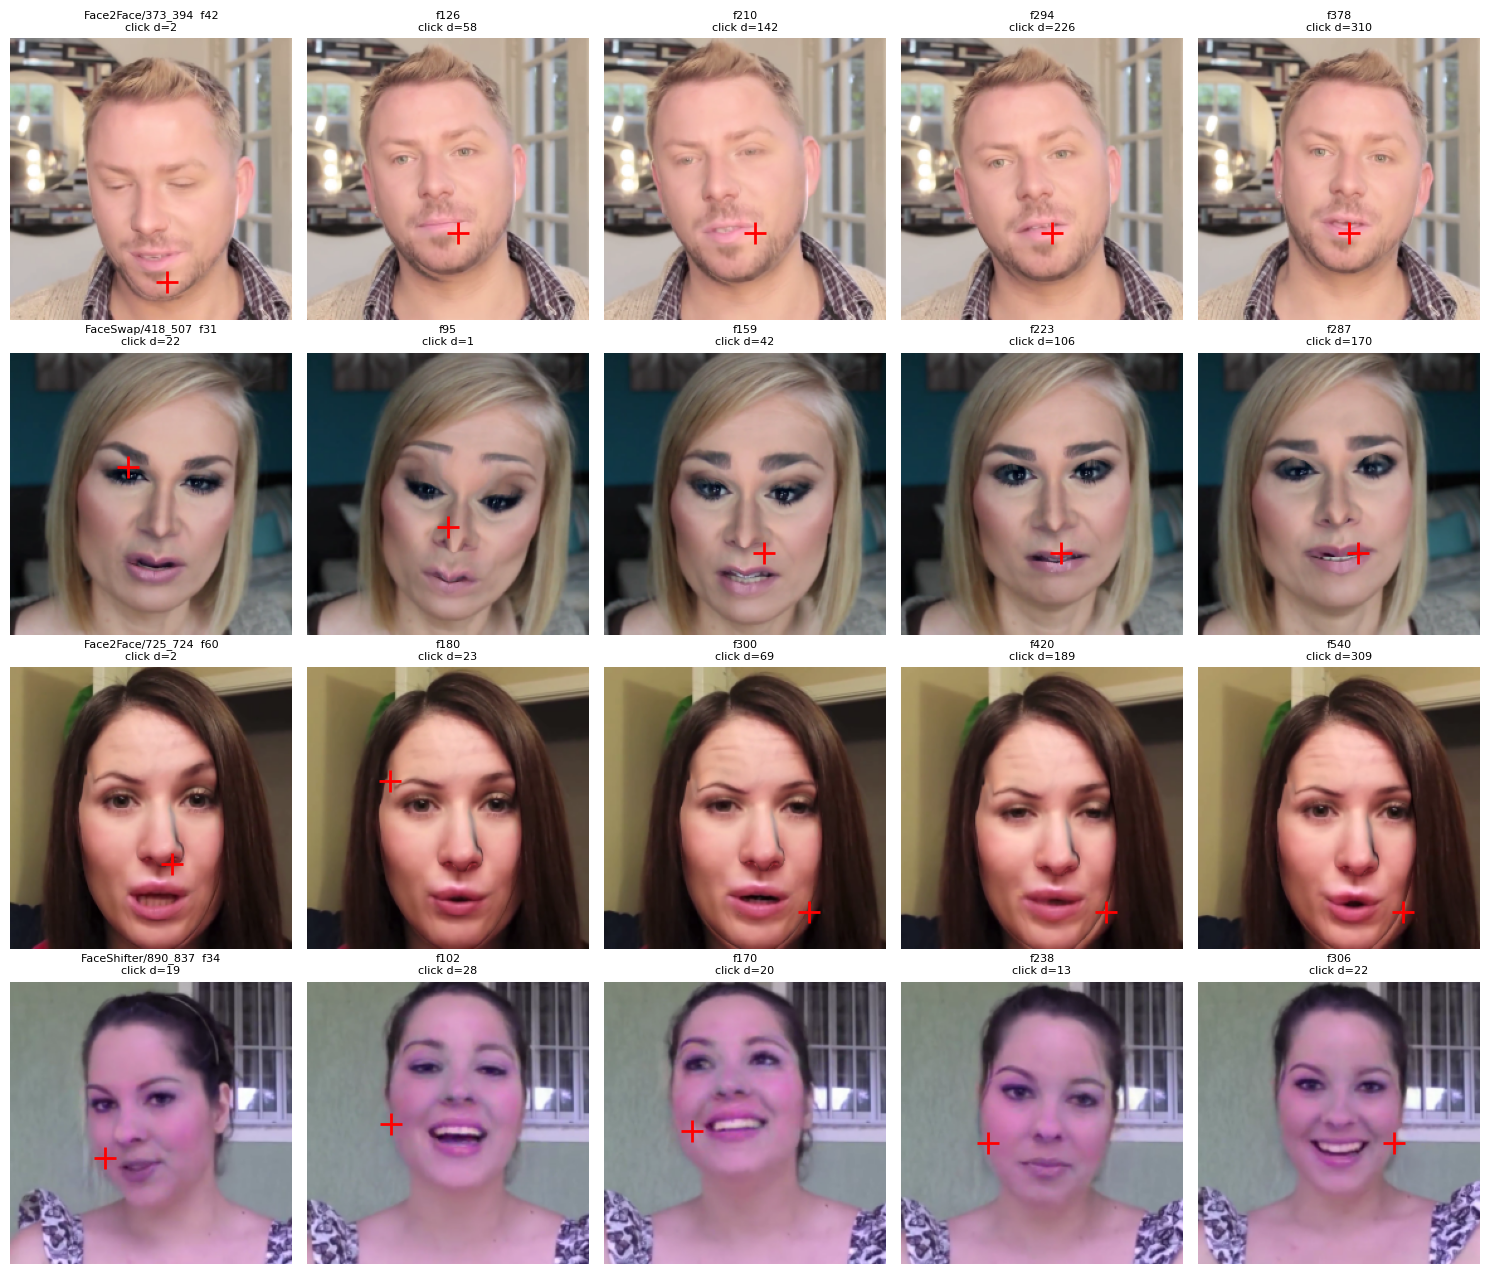

Face2Face/373_394 -> Artifacts and distortions on the mouth.
FaceSwap/418_507 -> Eyeliner marks are inconsistent and appear and disappear on the eyelids. Nose and mouth have distortions.
Face2Face/725_724 -> The face is not well rendered, as the source head is still visible behind. The mouth and nose experience glitches.
FaceShifter/890_837 -> THe area around the cheeks is blurred.


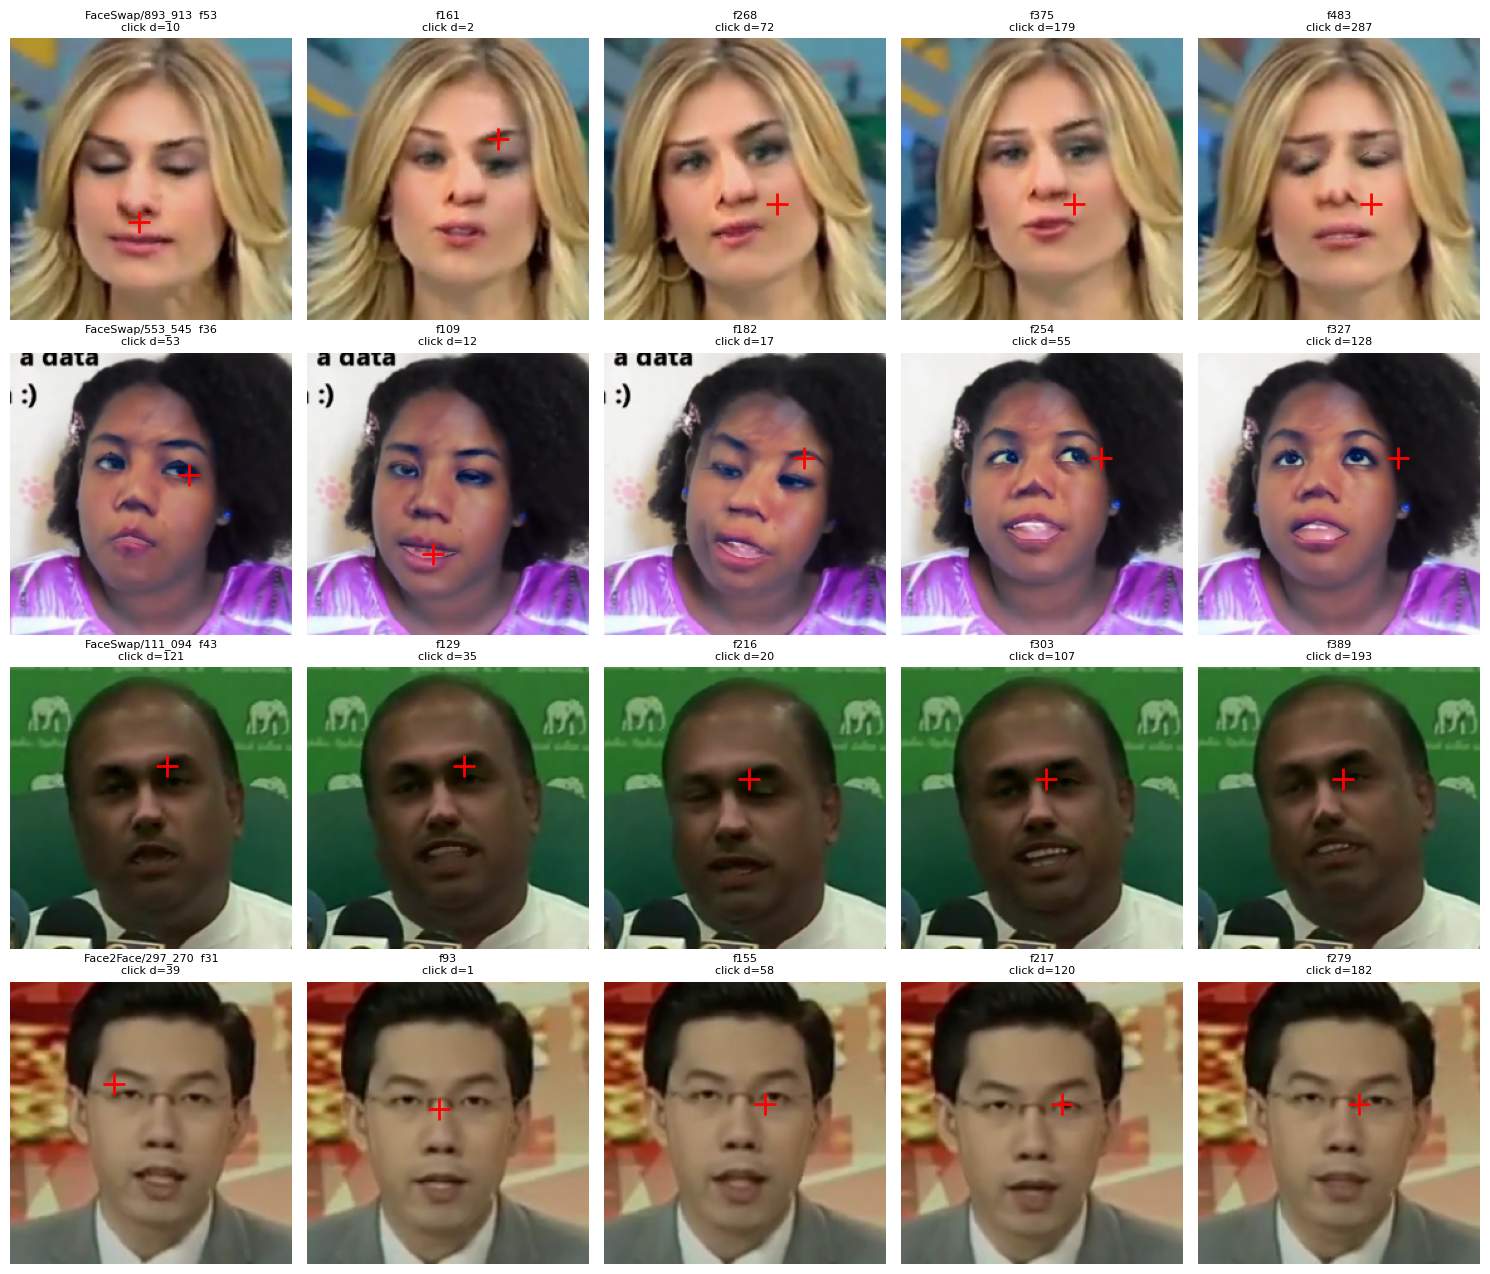

FaceSwap/893_913 -> The nose is heavily deformed and keeps shifting shape and orientation. There is significant distortion of the face and artifacts can be observed all over the fa
FaceSwap/553_545 -> The eyebrows are twitching slightly. The are artifacts around the eye area and some unusual black lines on the eyelids. There are artifacts around the mouth are
FaceSwap/111_094 -> Artifacts around the eyebrows.
Face2Face/297_270 -> The person seems to wear eyeglasses, but they have missing parts.


In [10]:
# flagged videos worth a look + a second random sample
flag = meta[(meta.n_det < 3) | (ratio > 0.95)].key.tolist()
print("flagged:", len(flag))
if flag: show_samples(random.Random(SEED).sample(flag, min(4, len(flag))))
show_samples(meta.sample(4, random_state=1).key.tolist())

## Next
- Attach this notebook's output as a Kaggle dataset (Output -> New Dataset). Notebooks 2-4 read `metadata.csv` and `crops/` from it.
- Known limitation to note in the write-up: every video gets **one** box (union of 5 detections), so a face that moves a lot ends up with a looser crop; and per-frame click targets are nearest-in-time clicks, not clicks on that exact frame.

In [12]:
import shutil
from IPython.display import FileLink

# 1. Zip the entire /kaggle/working directory
# Note: Do not include '.zip' in the first argument; shutil adds it automatically
shutil.make_archive('notebook1', 'zip', '/kaggle/working/prep')

# 2. Generate a clickable download link
FileLink(r'notebook1.zip')

/kaggle/working/notebook1.zip